# Audio Stella — pipeline đang chạy

Đọc kết quả inference đã lưu từ demo tại `127.0.0.1:8765`. Không chạy lại model/API khi mở notebook này. Câu tham chiếu do người dùng cung cấp chỉ dùng để chấm sau inference; không đưa vào ASR/BERT/Qwen. Đây là smoke test một bản thu, không phải accuracy trên một dataset.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Audio, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
OUT = ROOT / 'data/generated/user-stella-audio-20261023'
r = json.loads((OUT / 'result.json').read_text(encoding='utf-8'))
print('Audio:', r['source_file'])
print('Duration:', r['audio']['duration_sec'], 'seconds')
print('ASR:', r['models']['asr_model'], '| BERT:', r['config']['transcript_recovery_model'])
print('Câu chuẩn không gửi model:', not r['reference_supplied_to_model'])
print('Code giữ nguyên trong lượt đo:', not r['runtime_source_changed'])
display(Audio(filename=str(OUT / 'source_audio.wav')))

Audio: C:\Users\demod\Downloads\audio-file.mp3
Duration: 24.16025 seconds
ASR: wav2vec2-vi-en-v1 | BERT: google-bert/bert-base-uncased
Câu chuẩn không gửi model: True
Code giữ nguyên trong lượt đo: True


In [2]:
print('REFERENCE:')
print(r['reference'])
for stage in r['stages']:
    print('\n' + stage['stage'] + ' [' + str(stage['status']) + ']:')
    print(stage['text'])
print('\nBOT: ' + r['reply'])

REFERENCE:
Please call Stella. Ask her to bring these things with her from the store: Six spoons of fresh snow peas, five thick slabs of blue cheese, and maybe a snack for her brother Bob. We also need a small plastic snake and a big toy frog for the kids. She can scoop these things into three red bags, and we will go meet her Wednesday at the train station.

ASR [raw_audio_inference]:
Placoll tellar askd her to bring the things with her fromer stor six spoons of fresh nol beast five tick slap of blue sheats and may be a sneck for her brother bo we also need of small blaslik sneck and wit choy frog for the keys she can schoolle things into three red bags and w win go meet her wednesday ot the tran station

BERT [accepted]:
Pla coll tel lar askd her to bring the things with her fromer torr six spoons of fresh nol beast five tick slap of blue sheats and may be a sneck for her brother bo we also need of small blaslik sneck and wit choy frog for the keys she can schoolle things into three 

,stage,reference_words,hypothesis_words,substitution,deletion,insertion,word_errors,wer,exact_match
0,ASR,69,66,25,4,1,30,0.434783,False
1,BERT,69,68,26,3,2,31,0.449275,False
2,Conversation,69,68,26,3,2,31,0.449275,False


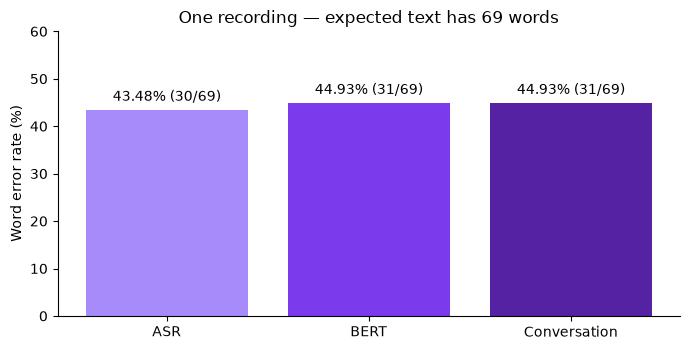

In [3]:
metrics = pd.DataFrame([{key: row[key] for key in (
    'stage', 'reference_words', 'hypothesis_words', 'substitution', 'deletion', 'insertion', 'word_errors', 'wer', 'exact_match')}
    for row in r['stages']])
display(metrics)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(metrics['stage'], metrics['wer'] * 100, color=['#a78bfa', '#7c3aed', '#5422a3'])
ax.bar_label(bars, labels=[f'{row["wer"]:.2%} ({row["word_errors"]}/69)' for row in r['stages']], padding=4)
ax.set(ylabel='Word error rate (%)', ylim=(0, 60), title='One recording — expected text has 69 words')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / 'wer.png', dpi=160)
plt.show()

In [4]:
for stage in r['stages'][:2]:
    print(stage['stage'] + ': word differences')
    display(pd.DataFrame([row for row in stage['alignment'] if row['op'] != 'equal']))

ASR: word differences


,op,reference,hypothesis,reference_index
0,deletion,please,,0
1,substitution,call,placoll,1
2,substitution,stella,tellar,2
3,substitution,ask,askd,3
4,substitution,these,the,7
5,deletion,from,,11
6,substitution,the,fromer,12
7,substitution,store,stor,13
8,substitution,snow,nol,18
9,substitution,peas,beast,19


BERT: word differences


,op,reference,hypothesis,reference_index
0,insertion,,pla,0
1,substitution,please,coll,0
2,substitution,call,tel,1
3,substitution,stella,lar,2
4,substitution,ask,askd,3
5,substitution,these,the,7
6,deletion,from,,11
7,substitution,the,fromer,12
8,substitution,store,torr,13
9,substitution,snow,nol,18


In [5]:
display(pd.DataFrame([r['timing']['speech_timings']['timings']]).T.rename(columns={0: 'seconds'}))
print('Reply visible:', r['timing']['reply_ready']['elapsed_sec'], 'seconds')
print('All feedback finished:', r['timing']['full_elapsed_sec'], 'seconds')
print('Qwen recovery:', r['conversation_recovery']['status'], r['conversation_recovery'].get('reason'))
print('Audio unchanged:', r['audio_unchanged'])
print('Voice API calls:', r['voice_api_calls'], '| Training:', r['training_started'])
assert not r['reference_supplied_to_model'] and not r['audio_sent_externally']
assert not r['runtime_source_changed'] and r['audio_unchanged']

,seconds
audio_decode_sec,0.015
asr_sec,2.860
reference_setup_sec,0.000
phoneme_sec,2.593
assessment_sec,0.000
reference_resolution_sec,0.000
phonetic_candidates_sec,0.000
interpretation_sec,1.734
reference_reassessment_sec,0.000
sentence_recovery_sec,4.562


Reply visible: 11.985 seconds
All feedback finished: 21.235 seconds
Qwen recovery: ambiguous unsupported_spelling_change
Audio unchanged: True
Voice API calls: 0 | Training: False


Kết quả hiện tại **chưa khôi phục đúng toàn đoạn**. BERT làm tăng WER ở ví dụ này; các sửa đổi `Placoll → pla coll`, `tellar → tel lar`, `stor → torr` không giải quyết đúng nội dung. Qwen recovery bị từ chối; lời nhắc nói lại do ứng dụng tạo. WER đo sai khác nhận dạng, không chứng minh người dùng phát âm sai. Câu chuẩn ở đây là kỳ vọng của người dùng, chưa có xác minh transcript bằng người nghe độc lập.